# Laboratorio 3 – La tarea de clasificación
**Grupo:** G11

**Integrantes:**
- Juan Diego Ramirez – 
- Sebastian Vargas Otero – 202323722

---
**Objetivo.** Construir, para cada uno de los dos tipos de cupón, un clasificador que anticipe si un conductor acepta (`Sí`) o no (`No`) el cupón ofrecido, comparando regresión logística, árboles de decisión y Random Forest; evaluar el efecto del balanceo de clases (SMOTE) en *Restaurante(<20)*; identificar las variables más influyentes y discutir los riesgos de sesgo de personalizar ofertas con datos demográficos.

**Contenido**
1. Exploración de los datos
2. Limpieza y preparación
3. Regresión logística
4. Árboles de decisión
5. Random Forest
6. Balanceo de clases (SMOTE) en Restaurante(<20)
7. Tabla comparativa y selección del mejor modelo
8. Variables más relevantes
9. Análisis de resultados
10. Predicciones sobre Lab3_datos_Prueba
11. Uso de herramientas de IA generativa

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import sklearn, imblearn
print("scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__, "| pandas", pd.__version__)

SEED = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
CUPONES = ["Cafetería", "Restaurante(<20)"]

scikit-learn 1.9.0 | imbalanced-learn 0.14.2 | pandas 3.0.5


## 1. Exploración de los datos

### 1.1 Carga y vista general

In [2]:
df_raw = pd.read_excel("Data/Lab3_Datos.xlsx")
dicc = pd.read_excel("Data/Lab3_diccionario_Datos.xlsx")
print("Dimensiones del conjunto completo:", df_raw.shape)
df_raw.head()

Dimensiones del conjunto completo: (12664, 26)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


In [3]:
with pd.option_context("display.max_colwidth", 200):
    display(dicc)

,Variable,Tipo,Descripción
0,destino,Categórica nominal,"Destino del trayecto en el momento en que se ofrece el cupón. Valores posibles: Casa, Sin lugar urgente, Trabajo."
1,acompanante,Categórica nominal,"Tipo de acompañante(s) en el vehículo al momento de la oferta. Valores posibles: Solo, Amigo(s), Hijo(s), Pareja."
2,clima,Categórica nominal,"Condición climática durante el trayecto. Valores posibles: Soleado, Lluvioso, Nevado."
3,temperatura,Numérica entero,"Temperatura ambiente en grados Fahrenheit. Variable de diseño de la encuesta: solo toma 3 valores fijos, asociados al clima. Rango: {30, 55, 80}."
4,hora,Categórica ordinal,"Hora del día en que ocurre el trayecto. Valores posibles (en orden): 7:00 a.m., 10:00 a.m., 2:00 p.m., 6:00 p.m., 10:00 p.m."
5,cupon,Categórica nominal,"Tipo de cupón ofrecido al conductor. Valores posibles: Bar, Cafetería, Comida para llevar, Restaurante(<20), Restaurante(20-50). Los valores <20 y 20-50 indican los gastos pormedios por persona pa..."
6,vigencia_cupon,Categórica nominal,"Tiempo de vigencia del cupón antes de expirar. Valores posibles: 2 horas, 1 día."
7,genero,Categórica nominal,"Género reportado por el conductor. Valores posibles: Femenino, Masculino."
8,edad,Categórica ordinal,"Rango de edad del conductor. Valores posibles (en orden): menor de 21, 21, 26, 31, 36, 41, 46, 50 o más."
9,estado_civil,Categórica nominal,"Estado civil del conductor. Valores posibles: Soltero(a), Casado(a), Unión libre, Divorciado(a), Viudo(a)."


In [4]:
print(df_raw["cupon"].value_counts(), "\n")
# El estudio solo se interesa en Cafetería y Restaurante(<20): se filtran esos dos subconjuntos
df = df_raw[df_raw["cupon"].isin(CUPONES)].copy()
print("Filas de interés:", len(df))
df["cupon"].value_counts()

cupon
Cafetería             3986
Restaurante(<20)      2776
Comida para llevar    2393
Bar                   2017
Restaurante(20-50)    1492
Name: count, dtype: int64 

Filas de interés: 6762


cupon
Cafetería           3986
Restaurante(<20)    2776
Name: count, dtype: int64

### 1.2 Calidad de los datos por subconjunto
Para cada cupón revisamos valores faltantes, duplicados, columnas constantes y cardinalidad.

In [5]:
def perfil_calidad(d):
    return pd.DataFrame({
        "tipo": d.dtypes.astype(str),
        "nulos": d.isna().sum(),
        "% nulos": (d.isna().mean() * 100).round(2),
        "n_valores": d.nunique(),
    })

for c in CUPONES:
    sub = df[df["cupon"] == c]
    print(f"===== {c}: {sub.shape[0]} filas | duplicados exactos: {sub.duplicated().sum()}")
    display(perfil_calidad(sub).query("nulos > 0 or n_valores <= 1"))

===== Cafetería: 3986 filas | duplicados exactos: 7


,tipo,nulos,% nulos,n_valores
cupon,str,0,0.00,1
vehiculo,str,3949,99.07,5
frecuencia_bar,str,37,0.93,5
frecuencia_cafeteria,str,72,1.81,5
frecuencia_comida_para_llevar,str,57,1.43,5
frecuencia_restaurante_menos_20,str,50,1.25,5
frecuencia_restaurante_20_a_50,str,55,1.38,5
tiempo_cupon_mayor_5min,str,0,0.00,1


===== Restaurante(<20): 2776 filas | duplicados exactos: 7


,tipo,nulos,% nulos,n_valores
cupon,str,0,0.00,1
vehiculo,str,2751,99.10,5
frecuencia_bar,str,23,0.83,5
frecuencia_cafeteria,str,47,1.69,5
frecuencia_comida_para_llevar,str,34,1.22,5
frecuencia_restaurante_menos_20,str,27,0.97,5
frecuencia_restaurante_20_a_50,str,43,1.55,5
tiempo_cupon_mayor_5min,str,0,0.00,1


In [6]:
# Valores posibles de cada variable categórica (para detectar inconsistencias de escritura)
for col in df.columns.drop(["temperatura"]):
    print(f"{col:35s} {sorted(df[col].dropna().astype(str).unique())}")

destino                             ['Casa', 'Sin lugar urgente', 'Trabajo']
acompanante                         ['Amigo(s)', 'Hijo(s)', 'Pareja', 'Solo']
clima                               ['Lluvioso', 'Nevado', 'Soleado']
hora                                ['10:00 a.m.', '10:00 p.m.', '2:00 p.m.', '6:00 p.m.', '7:00 a.m.']
cupon                               ['Cafetería', 'Restaurante(<20)']
vigencia_cupon                      ['1 día', '2 horas']
genero                              ['Femenino', 'Masculino']
edad                                ['21', '26', '31', '36', '41', '46', '50 o más', 'menor de 21']
estado_civil                        ['Casado(a)', 'Divorciado(a)', 'Soltero(a)', 'Unión libre', 'Viudo(a)']
tiene_hijos                         ['No', 'Sí']
educacion                           ['Bachillerato completo', 'Bachillerato incompleto', 'Estudios universitarios sin título', 'Posgrado (Maestría o Doctorado)', 'Pregrado', 'Técnico/Tecnólogo']
ocupacion                     

### 1.3 Posibles redundancias
El diccionario indica que `temperatura` es una variable de diseño asociada al clima y que existen dos variables de dirección. Lo verificamos.

In [7]:
display(pd.crosstab(df["misma_direccion"], df["direccion_opuesta"]))
display(pd.crosstab(df["clima"], df["temperatura"]))
display(pd.crosstab(df["tiempo_cupon_mayor_15min"], df["tiempo_cupon_mayor_25min"]))
print("Valores de tiempo_cupon_mayor_5min:", df["tiempo_cupon_mayor_5min"].unique())

direccion_opuesta,No,Sí
misma_direccion,,
No,0,5514
Sí,1248,0


temperatura,30,55,80
clima,,,
Lluvioso,0,394,0
Nevado,678,0,0
Soleado,187,1542,3961


tiempo_cupon_mayor_25min,No,Sí
tiempo_cupon_mayor_15min,,
No,3452,0
Sí,2690,620


Valores de tiempo_cupon_mayor_5min: <StringArray>
['Sí']
Length: 1, dtype: str


### 1.4 Distribución de la variable objetivo `acepta_cupon`

conteo           %      
acepta_cupon         No    Sí    No    Sí
cupon                                    
Cafetería          1997  1989  50.1  49.9
Restaurante(<20)    814  1962  29.3  70.7

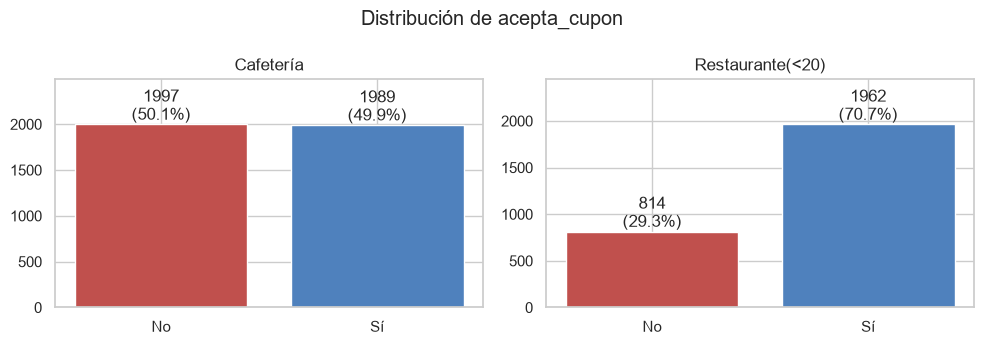

In [8]:
dist = pd.crosstab(df["cupon"], df["acepta_cupon"])
dist_pct = pd.crosstab(df["cupon"], df["acepta_cupon"], normalize="index").mul(100).round(1)
display(pd.concat({"conteo": dist, "%": dist_pct}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, c in zip(axes, CUPONES):
    s = df.loc[df["cupon"] == c, "acepta_cupon"].value_counts().reindex(["No", "Sí"])
    ax.bar(s.index, s.values, color=["#c0504d", "#4f81bd"])
    for i, v in enumerate(s.values):
        ax.text(i, v, f"{v}\n({v / s.sum():.1%})", ha="center", va="bottom")
    ax.set_title(c); ax.set_ylim(0, s.max() * 1.25)
plt.suptitle("Distribución de acepta_cupon"); plt.tight_layout(); plt.show()

### 1.5 Tasa de aceptación según las variables
Proporción de `Sí` por categoría de cada variable, separada por cupón. Sirve como primera aproximación a qué factores se relacionan con la aceptación.

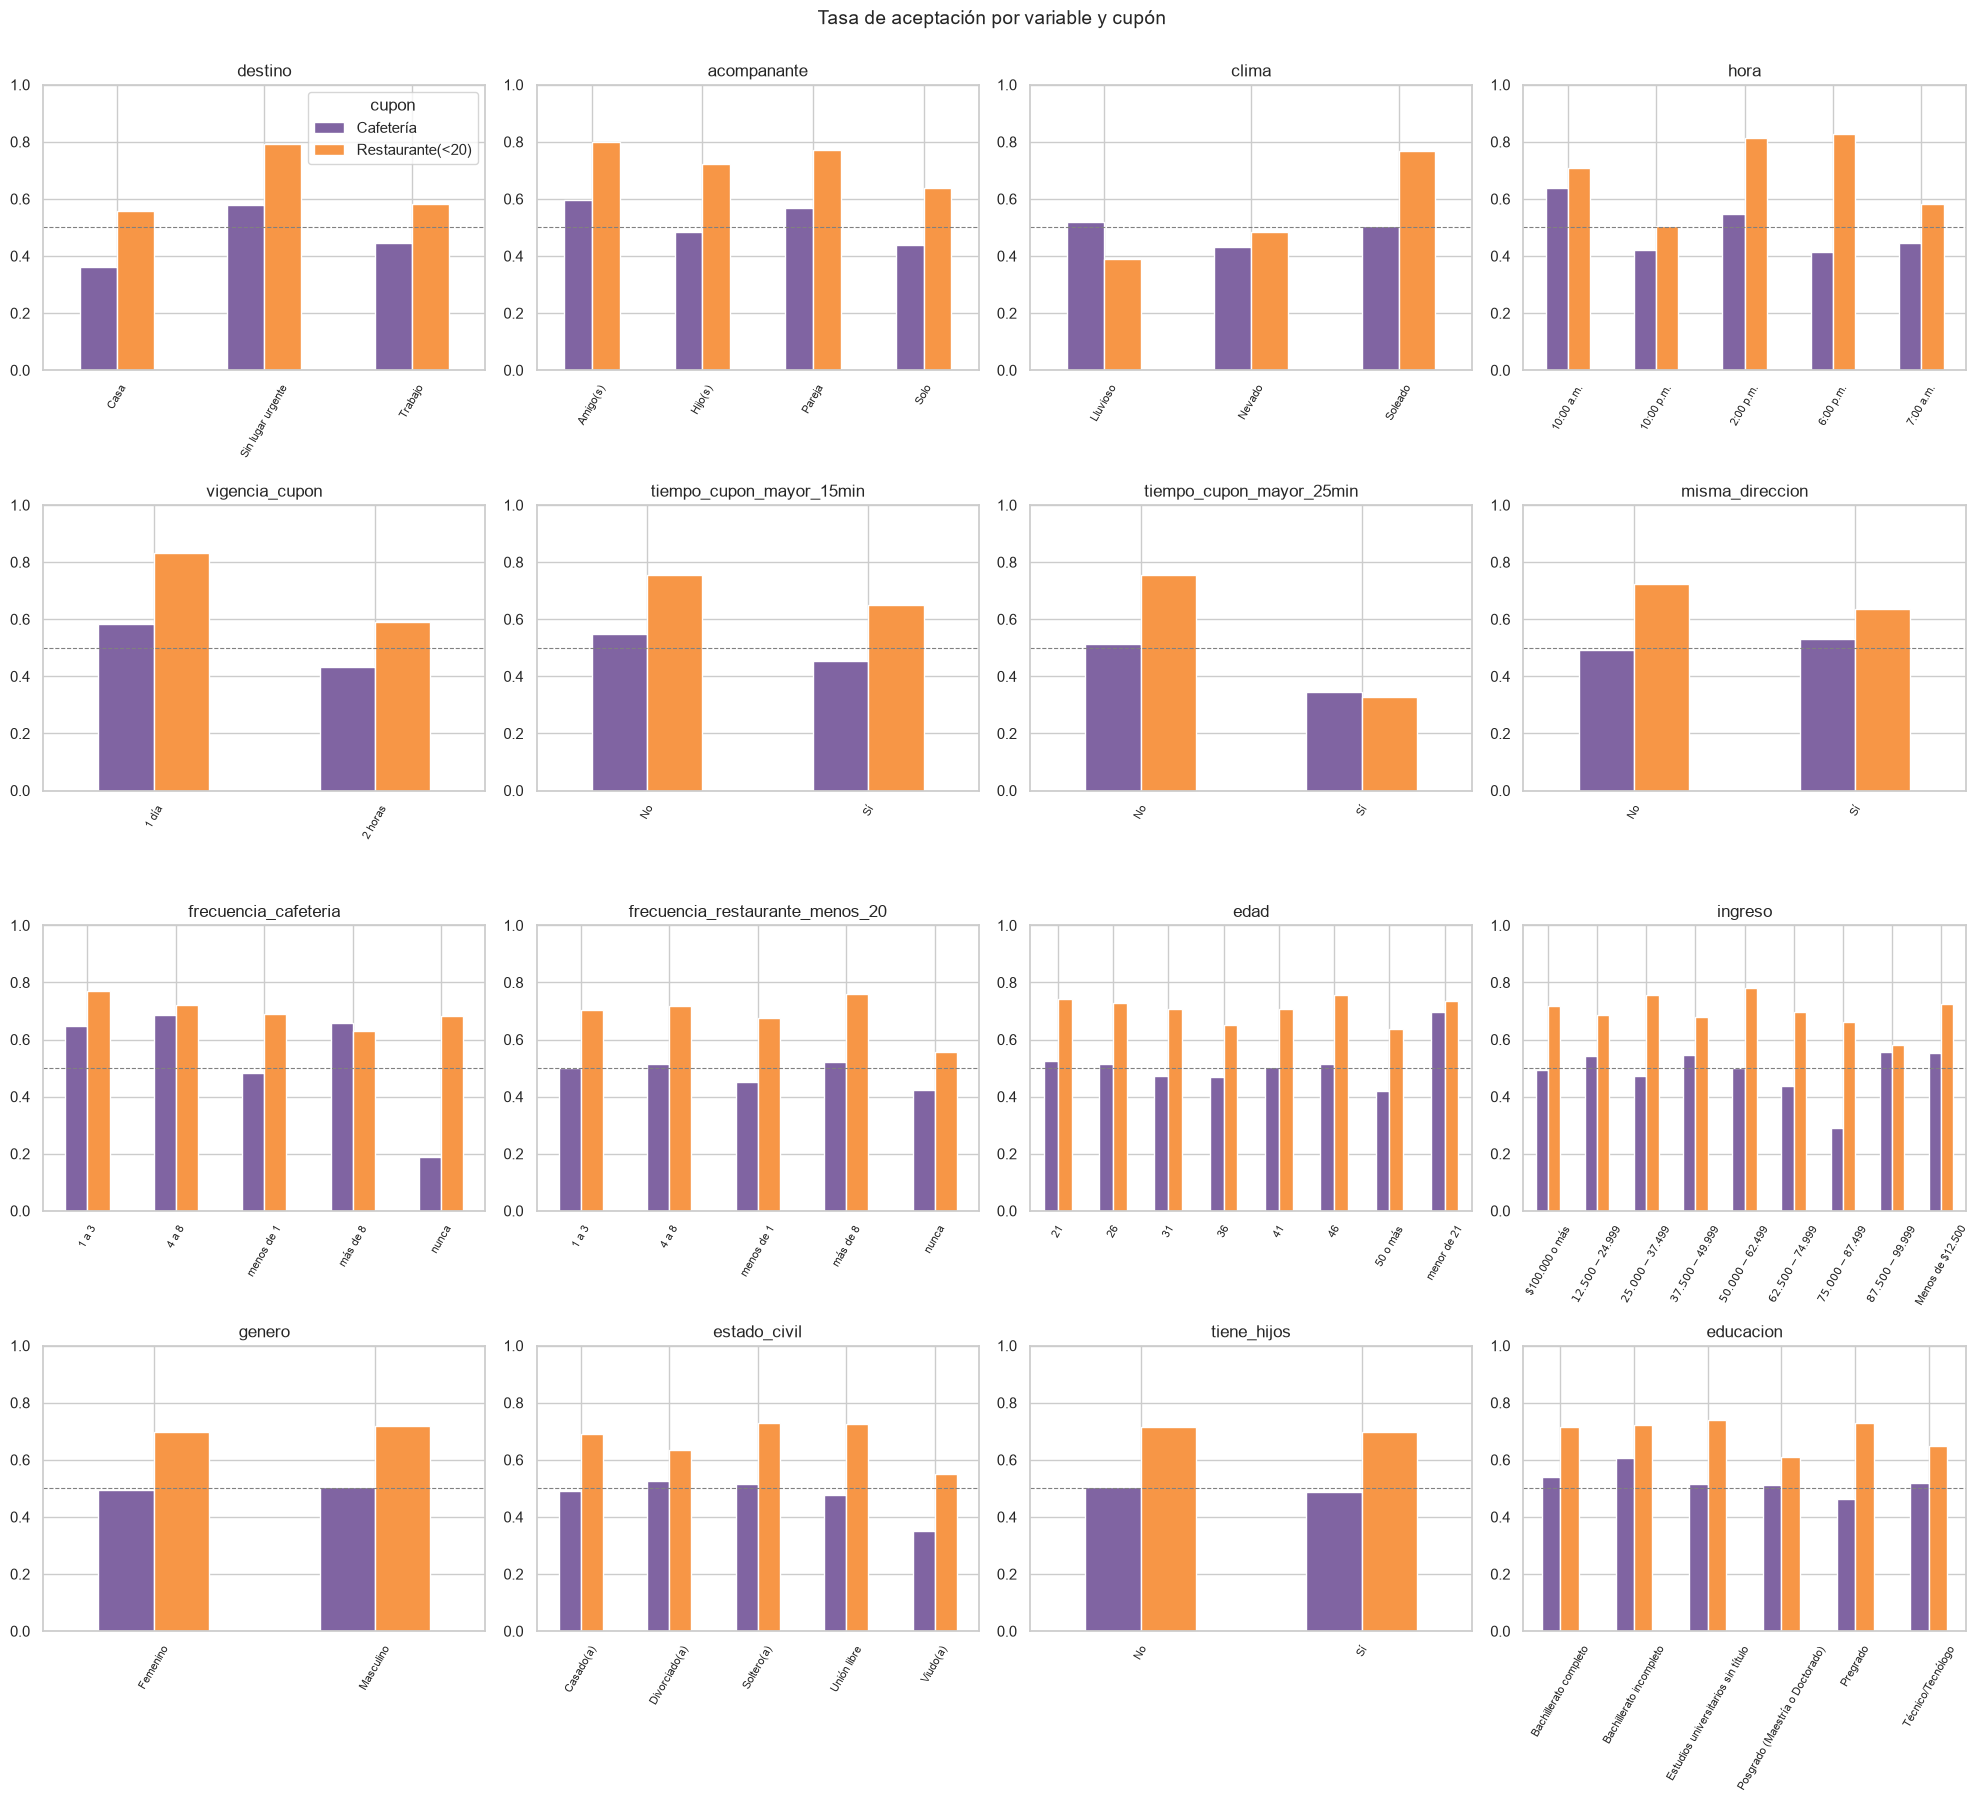

In [9]:
vars_plot = ["destino", "acompanante", "clima", "hora", "vigencia_cupon", "tiempo_cupon_mayor_15min",
             "tiempo_cupon_mayor_25min", "misma_direccion", "frecuencia_cafeteria",
             "frecuencia_restaurante_menos_20", "edad", "ingreso", "genero", "estado_civil",
             "tiene_hijos", "educacion"]
tmp = df.assign(y=(df["acepta_cupon"] == "Sí").astype(int))
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for ax, v in zip(axes.ravel(), vars_plot):
    t = tmp.groupby([v, "cupon"])["y"].mean().unstack()
    t.plot.bar(ax=ax, legend=(v == vars_plot[0]), color=["#8064a2", "#f79646"])
    ax.set_title(v); ax.set_xlabel(""); ax.set_ylim(0, 1); ax.axhline(0.5, ls="--", c="grey", lw=0.8)
    ax.tick_params(axis="x", labelsize=8, rotation=60)
plt.suptitle("Tasa de aceptación por variable y cupón", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

In [10]:
# Ocupación tiene muchas categorías: la mostramos aparte
t = tmp.groupby(["ocupacion", "cupon"])["y"].agg(["mean", "size"]).unstack()
t.sort_values(("mean", "Cafetería")).round(2)

mean                       size                 
cupon                                             Cafetería Restaurante(<20) Cafetería Restaurante(<20)
ocupacion                                                                                              
Servicios Comunitarios y Sociales                      0.35             0.70        74               50
Producción                                             0.36             0.76        28               25
Área Legal                                             0.38             0.59        69               49
Ventas y afines                                        0.39             0.80       354              237
Jubilado(a)                                            0.40             0.59       163              111
Apoyo Administrativo y de Oficina                      0.43             0.76       195              135
Educación, Formación y Bibliotecología                 0.44             0.69       296              220
Preparación y Servicio de Alimentos                    0.45             0.71        83               69
Servicios de Protección y Seguridad                    0.45             0.89        58               38
Gerencia                                               0.46             0.73       297              187
Ciencias Naturales y Sociales                          0.48             0.83        61               36
Construcción y Extracción                              0.48             0.89        46               35
Negocios y Finanzas                                    0.48             0.67       146              126
Cuidado Personal y Servicios                           0.50             0.58        50               38
Computación y Matemáticas                              0.50             0.70       447              298
Artes, Diseño, Entretenimiento, Deportes y Medios      0.51             0.65       209              136
Desempleado(a)                                         0.54             0.67       569              409
Agricultura, Pesca y Silvicultura                      0.55             0.57        11                7
Arquitectura e Ingeniería                              0.55             0.79        62               39
Instalación, Mantenimiento y Reparación                0.57             0.70        44               27
Transporte y Manejo de Materiales                      0.61             0.76        75               45
Apoyo en Salud                                         0.62             0.74        65               53
Estudiante                                             0.63             0.71       499              345
Limpieza y Mantenimiento de Edificios                  0.73             0.40        11               10
Profesionales y Técnicos de la Salud                   0.74             0.69        74               51

### 1.6 Conclusiones de la exploración

**Tamaño y balance**
- *Cafetería*: 3.986 registros, **balanceado** (50,1% `No` / 49,9% `Sí`).
- *Restaurante(<20)*: 2.776 registros, **desbalanceado** (70,7% `Sí` / 29,3% `No`). La clase minoritaria es `No`, de modo que un modelo trivial que siempre diga `Sí` ya logra ≈ 71% de *accuracy*. Por eso no usamos *accuracy* como métrica principal.

**Problemas de calidad**
- `vehiculo`: ≈ 99% de nulos, inservible.
- `frecuencia_*`: entre 1% y 2% de nulos (MCAR aparente, sin patrón por cupón).
- `tiempo_cupon_mayor_5min`: constante (`Sí` en todas las filas).
- `direccion_opuesta` es exactamente el complemento de `misma_direccion` (la tabla cruzada no tiene casos fuera de la antidiagonal).
- `tiempo_cupon_mayor_25min = Sí` implica `tiempo_cupon_mayor_15min = Sí`: están anidadas.
- `temperatura` está casi determinada por `clima` (Nevado → 30, Lluvioso → 55); solo dentro de `Soleado` toma valores distintos.
- 7 duplicados exactos en cada subconjunto.
- No hay inconsistencias de escritura en las categorías.
- Hay variables **ordinales** escritas como texto (`edad`, `ingreso`, `hora`, `educacion`, `frecuencia_*`) que requieren una codificación con orden explícito.

**Primeras relaciones con la aceptación**
- *Cafetería*: la variable más marcada es **`frecuencia_cafeteria`**. Quien nunca va a cafeterías acepta solo el 19% de las veces, frente a 65–69% de quien va 1 a 8 veces al mes. Le siguen:
  - el **destino** (58% sin lugar urgente vs 36% hacia casa);
  - la **hora** (64% a las 10 a.m. vs ≈ 41% a las 6 p.m. y 10 p.m.);
  - la **vigencia** (58% con 1 día vs 43% con 2 horas);
  - la **distancia** (35% si el lugar está a más de 25 min).
- *Restaurante(<20)*: domina el **contexto del trayecto** más que el hábito declarado:
  - **clima** (77% con sol vs 39% con lluvia);
  - **distancia mayor a 25 min** (33% vs 75%);
  - **vigencia** (83% con 1 día vs 59%);
  - **hora** (81–83% a las 2 y 6 p.m. vs 51% a las 10 p.m.);
  - **destino** y **acompañante** (más aceptación con amigos o pareja que solo).
- Las variables demográficas (`genero`, `tiene_hijos`, `edad`, `ingreso`) muestran **diferencias pequeñas** en tasa de aceptación, salvo algunos grupos poco numerosos (p. ej. viudos o menores de 21). Esas diferencias pueden ser ruido muestral.

## 2. Limpieza y preparación de los datos

Decisiones tomadas a partir de la exploración:

| Problema / característica | Decisión | Justificación |
|---|---|---|
| `vehiculo` con ~99% de nulos | Eliminar | No hay información suficiente para imputar ni aporta señal. |
| `tiempo_cupon_mayor_5min` constante (siempre `Sí`) | Eliminar | Varianza cero, no discrimina. |
| `direccion_opuesta` = complemento exacto de `misma_direccion` | Eliminar `direccion_opuesta` | Redundancia perfecta (colinealidad en la regresión logística). |
| `cupon` constante dentro de cada subconjunto | Eliminar tras filtrar | Se entrena un modelo por cupón. |
| Filas duplicadas exactas | Eliminar antes de dividir train/test | Evita que una misma observación quede en train y test (fuga de información) y que pese doble. |
| Nulos en `frecuencia_*` (< 5%) | Imputar con la moda **dentro del pipeline** | Pocos nulos; la moda se calcula solo con train en cada fold, sin fuga. |
| Variables ordinales (`hora`, `edad`, `ingreso`, `educacion`, `frecuencia_*`, `vigencia_cupon`) y binarias Sí/No | `OrdinalEncoder` con orden explícito | Conserva el orden natural y evita multiplicar columnas. |
| Variables nominales (`destino`, `acompanante`, `clima`, `genero`, `estado_civil`, `ocupacion`) | `OneHotEncoder(handle_unknown="ignore")` | No tienen orden; `ignore` protege ante categorías nuevas en producción. |
| Escalas distintas | `StandardScaler` solo para la regresión logística | La regularización L1/L2 depende de la escala; los árboles son invariantes. |
| `temperatura` (3 valores, ligada al clima) | Se conserva como numérica | Aporta matices dentro de `Soleado` (55 vs 80 °F); se evalúa su relevancia en la sección 8. |
| Variable objetivo | `Sí` → 1, `No` → 0 | Clase positiva = acepta el cupón. |

In [11]:
DROP_COLS = ["vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta", "cupon"]
FREQ = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
SI_NO = ["No", "Sí"]
ORD_CATS = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "vigencia_cupon": ["2 horas", "1 día"],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
    **{c: FREQ for c in ["frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
                         "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50"]},
    **{c: SI_NO for c in ["tiene_hijos", "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min",
                          "misma_direccion"]},
}
ORD_COLS = list(ORD_CATS)
NOM_COLS = ["destino", "acompanante", "clima", "genero", "estado_civil", "ocupacion"]
NUM_COLS = ["temperatura"]
FEATURES = NUM_COLS + ORD_COLS + NOM_COLS


def limpiar(d):
    # Homogeneiza tipos: categóricas como texto (object) y nulos como np.nan
    d = d.drop(columns=[c for c in DROP_COLS if c in d.columns]).copy()
    for c in ORD_COLS + NOM_COLS:
        d[c] = d[c].map(lambda v: str(v) if pd.notna(v) else np.nan).astype(object)
    d["temperatura"] = d["temperatura"].astype(float)
    return d


# Verificación: todas las categorías observadas están en los órdenes definidos
for c, cats in ORD_CATS.items():
    extra = set(df[c].dropna().astype(str)) - set(cats)
    assert not extra, (c, extra)
print("Órdenes de las variables ordinales verificados.")

Órdenes de las variables ordinales verificados.


In [12]:
def preprocesador(escalar):
    ord_steps = [("imp", SimpleImputer(strategy="most_frequent")),
                 ("enc", OrdinalEncoder(categories=[ORD_CATS[c] for c in ORD_COLS],
                                        handle_unknown="use_encoded_value", unknown_value=-1))]
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        ord_steps.append(("sc", StandardScaler()))
        num_steps.append(("sc", StandardScaler()))
    nom = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", Pipeline(num_steps), NUM_COLS),
                              ("ord", Pipeline(ord_steps), ORD_COLS),
                              ("nom", nom, NOM_COLS)],
                             verbose_feature_names_out=False)


datos = {}
for c in CUPONES:
    sub = df[df["cupon"] == c]
    n0 = len(sub)
    sub = sub.drop_duplicates()
    sub = limpiar(sub)
    X, y = sub[FEATURES], (sub["acepta_cupon"] == "Sí").astype(int)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    datos[c] = dict(X=X, y=y, X_tr=X_tr, X_te=X_te, y_tr=y_tr, y_te=y_te)
    print(f"{c:18s} filas {n0} -> {len(sub)} sin duplicados | train {len(X_tr)} | test {len(X_te)} "
          f"| % Sí train {y_tr.mean():.1%} test {y_te.mean():.1%}")

print("\nDimensión tras el preprocesamiento (Cafetería):",
      preprocesador(True).fit_transform(datos["Cafetería"]["X_tr"]).shape)

Cafetería          filas 3986 -> 3979 sin duplicados | train 3183 | test 796 | % Sí train 49.8% test 49.9%
Restaurante(<20)   filas 2776 -> 2769 sin duplicados | train 2215 | test 554 | % Sí train 70.7% test 70.8%

Dimensión tras el preprocesamiento (Cafetería): (3183, 57)


### 2.1 Protocolo de entrenamiento y evaluación
- Partición **80/20 estratificada** por cupón (`random_state=42`); el test solo se usa para la evaluación final.
- `GridSearchCV` con **validación cruzada estratificada de 5 folds** sobre train. Todo el preprocesamiento va dentro del pipeline, así que imputación, codificación y escalado se ajustan solo con los datos de entrenamiento de cada fold.
- **Métrica de selección: F1 macro.** Promedia el F1 de ambas clases, de modo que un modelo que ignore la clase minoritaria (los `No` en Restaurante(<20)) queda penalizado. Además reportamos precisión, recall y F1 de cada clase.

In [13]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
resultados = []   # métricas en test de cada modelo
modelos = {}      # (cupón, nombre) -> GridSearchCV ajustado


def metricas(y_true, y_pred):
    return {
        "precision_Sí": precision_score(y_true, y_pred, pos_label=1),
        "recall_Sí": recall_score(y_true, y_pred, pos_label=1),
        "f1_Sí": f1_score(y_true, y_pred, pos_label=1),
        "precision_No": precision_score(y_true, y_pred, pos_label=0),
        "recall_No": recall_score(y_true, y_pred, pos_label=0),
        "f1_No": f1_score(y_true, y_pred, pos_label=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }


def entrenar(cupon, nombre, clf, grid, escalar=False, smote=False):
    d = datos[cupon]
    if smote:
        pipe = ImbPipeline([("prep", preprocesador(escalar)), ("smote", SMOTE(random_state=SEED)), ("clf", clf)])
    else:
        pipe = Pipeline([("prep", preprocesador(escalar)), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=CV, n_jobs=-1, refit=True)
    gs.fit(d["X_tr"], d["y_tr"])
    y_pred = gs.predict(d["X_te"])
    m = metricas(d["y_te"], y_pred)
    resultados.append({"cupon": cupon, "modelo": nombre, "f1_macro_cv": gs.best_score_, **m})
    modelos[(cupon, nombre)] = gs
    print(f"--- {cupon} | {nombre} ---")
    print("Mejores hiperparámetros:", gs.best_params_)
    print(f"F1 macro CV: {gs.best_score_:.4f} | F1 macro test: {m['f1_macro']:.4f}")
    print(classification_report(d["y_te"], y_pred, target_names=["No", "Sí"], digits=3))
    return gs


def matrices(nombre):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, c in zip(axes, CUPONES):
        d = datos[c]
        ConfusionMatrixDisplay.from_estimator(modelos[(c, nombre)], d["X_te"], d["y_te"],
                                              display_labels=["No", "Sí"], cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(f"{c}")
    plt.suptitle(f"Matrices de confusión en test – {nombre}"); plt.tight_layout(); plt.show()

## 3. Regresión logística

Exploramos el **tipo de regularización**, el **solver** y la fuerza de regularización `C`. En scikit-learn ≥ 1.8 el parámetro `penalty` está obsoleto y el tipo de regularización se controla con `l1_ratio`: `0` = L2 (Ridge), `1` = L1 (Lasso) y valores intermedios = Elastic-Net. Como no todos los solvers admiten todas las penalizaciones, la rejilla se arma como una lista de diccionarios compatibles:
- `lbfgs` y `newton-cg`: solo L2, más el caso sin regularización (`C = ∞`).
- `liblinear`: L1 o L2.
- `saga`: L1, L2 y Elastic-Net.

--- Cafetería | Regresión logística ---
Mejores hiperparámetros: {'clf__C': 0.1, 'clf__l1_ratio': 0, 'clf__solver': 'lbfgs'}
F1 macro CV: 0.7103 | F1 macro test: 0.6922
              precision    recall  f1-score   support

          No      0.696     0.684     0.690       399
          Sí      0.688     0.700     0.694       397

    accuracy                          0.692       796
   macro avg      0.692     0.692     0.692       796
weighted avg      0.692     0.692     0.692       796



--- Restaurante(<20) | Regresión logística ---
Mejores hiperparámetros: {'clf__C': 1, 'clf__l1_ratio': 0, 'clf__solver': 'saga'}
F1 macro CV: 0.6591 | F1 macro test: 0.6519
              precision    recall  f1-score   support

          No      0.608     0.383     0.470       162
          Sí      0.779     0.898     0.834       392

    accuracy                          0.747       554
   macro avg      0.693     0.640     0.652       554
weighted avg      0.729     0.747     0.728       554



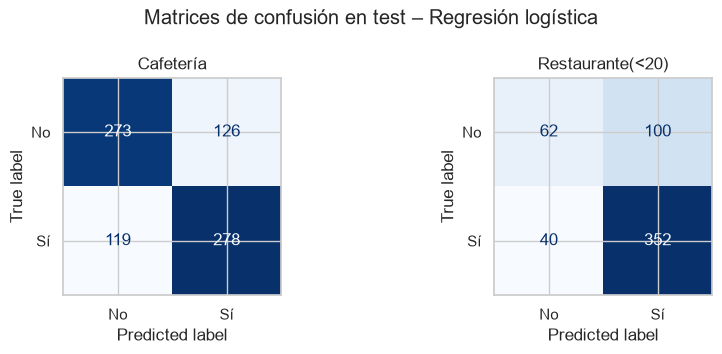

In [14]:
Cs = [0.01, 0.1, 1, 10, 100]
grid_lr = [
    {"clf__solver": ["lbfgs", "newton-cg"], "clf__l1_ratio": [0], "clf__C": Cs},
    {"clf__solver": ["lbfgs"], "clf__C": [np.inf]},                                   # sin regularización
    {"clf__solver": ["liblinear"], "clf__l1_ratio": [0, 1], "clf__C": Cs},
    {"clf__solver": ["saga"], "clf__l1_ratio": [0, 0.5, 1], "clf__C": Cs},
]
lr = LogisticRegression(max_iter=5000, random_state=SEED)
for c in CUPONES:
    entrenar(c, "Regresión logística", lr, grid_lr, escalar=True)
matrices("Regresión logística")

In [15]:
# Resumen de la búsqueda: mejor F1 CV por solver y tipo de regularización
def tipo_reg(r):
    if np.isinf(r["param_clf__C"]): return "ninguna"
    return {0: "L2", 1: "L1", 0.5: "Elastic-Net"}[r["param_clf__l1_ratio"]]

for c in CUPONES:
    cvr = pd.DataFrame(modelos[(c, "Regresión logística")].cv_results_)
    cvr["param_clf__l1_ratio"] = cvr["param_clf__l1_ratio"].fillna(0)
    cvr["regularización"] = cvr.apply(tipo_reg, axis=1)
    print(c)
    display(cvr.pivot_table(index="param_clf__solver", columns="regularización",
                            values="mean_test_score", aggfunc="max").round(4))

Cafetería


regularización,Elastic-Net,L1,L2,ninguna
param_clf__solver,,,,
lbfgs,NaN,NaN,0.7103,0.7046
liblinear,NaN,0.7078,0.7093,NaN
newton-cg,NaN,NaN,0.7090,NaN
saga,0.7071,0.7078,0.7090,NaN


Restaurante(<20)


regularización,Elastic-Net,L1,L2,ninguna
param_clf__solver,,,,
lbfgs,NaN,NaN,0.6587,0.6571
liblinear,NaN,0.6584,0.6587,NaN
newton-cg,NaN,NaN,0.6587,NaN
saga,0.6575,0.6580,0.6591,NaN


## 4. Árboles de decisión
Exploramos la **profundidad máxima**, el **mínimo de muestras por hoja** y el **criterio de división** (`gini`, `entropy`, `log_loss`). Los árboles no necesitan escalado.

--- Cafetería | Árbol de decisión ---
Mejores hiperparámetros: {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_leaf': 40}
F1 macro CV: 0.7126 | F1 macro test: 0.6836
              precision    recall  f1-score   support

          No      0.711     0.624     0.665       399
          Sí      0.664     0.746     0.702       397

    accuracy                          0.685       796
   macro avg      0.688     0.685     0.684       796
weighted avg      0.688     0.685     0.684       796



--- Restaurante(<20) | Árbol de decisión ---
Mejores hiperparámetros: {'clf__criterion': 'gini', 'clf__max_depth': 10, 'clf__min_samples_leaf': 20}
F1 macro CV: 0.6863 | F1 macro test: 0.6633
              precision    recall  f1-score   support

          No      0.643     0.389     0.485       162
          Sí      0.783     0.911     0.842       392

    accuracy                          0.758       554
   macro avg      0.713     0.650     0.663       554
weighted avg      0.742     0.758     0.737       554



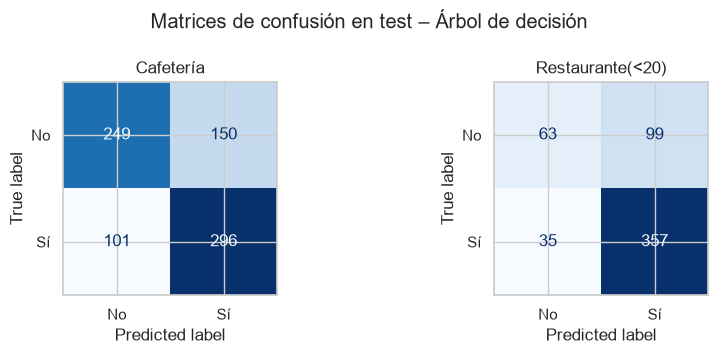

In [16]:
grid_dt = {
    "clf__max_depth": [3, 4, 5, 6, 8, 10, 15, None],
    "clf__min_samples_leaf": [1, 5, 10, 20, 40],
    "clf__criterion": ["gini", "entropy", "log_loss"],
}
dt = DecisionTreeClassifier(random_state=SEED)
for c in CUPONES:
    entrenar(c, "Árbol de decisión", dt, grid_dt)
matrices("Árbol de decisión")

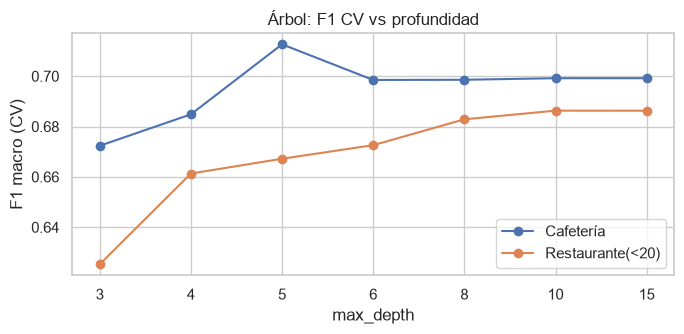

In [17]:
# Efecto de la profundidad (mejor combinación de los demás hiperparámetros para cada profundidad)
fig, ax = plt.subplots(figsize=(7, 3.5))
for c in CUPONES:
    cvr = pd.DataFrame(modelos[(c, "Árbol de decisión")].cv_results_)
    s = cvr.groupby(cvr["param_clf__max_depth"].astype(str))["mean_test_score"].max()
    s = s.reindex([str(v) for v in grid_dt["clf__max_depth"]])
    ax.plot(s.index, s.values, marker="o", label=c)
ax.set_xlabel("max_depth"); ax.set_ylabel("F1 macro (CV)"); ax.legend(); ax.set_title("Árbol: F1 CV vs profundidad")
plt.tight_layout(); plt.show()

## 5. Random Forest
Exploramos el **número de árboles**, la **profundidad máxima** y el **mínimo de muestras por hoja**. También incluimos `max_features`, que controla la decorrelación entre los árboles.

--- Cafetería | Random Forest ---
Mejores hiperparámetros: {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}
F1 macro CV: 0.7617 | F1 macro test: 0.7789
              precision    recall  f1-score   support

          No      0.779     0.779     0.779       399
          Sí      0.778     0.778     0.778       397

    accuracy                          0.779       796
   macro avg      0.779     0.779     0.779       796
weighted avg      0.779     0.779     0.779       796



--- Restaurante(<20) | Random Forest ---
Mejores hiperparámetros: {'clf__max_depth': None, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300}
F1 macro CV: 0.7041 | F1 macro test: 0.6851
              precision    recall  f1-score   support

          No      0.680     0.420     0.519       162
          Sí      0.793     0.918     0.851       392

    accuracy                          0.773       554
   macro avg      0.736     0.669     0.685       554
weighted avg      0.760     0.773     0.754       554



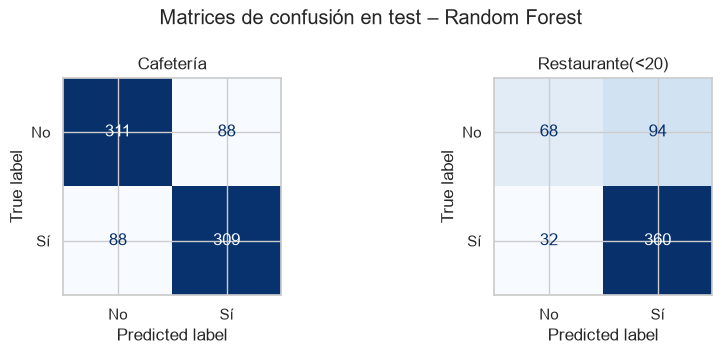

In [18]:
grid_rf = {
    "clf__n_estimators": [100, 300, 500],
    "clf__max_depth": [8, 15, 25, None],
    "clf__min_samples_leaf": [1, 3, 5, 10],
    "clf__max_features": ["sqrt", 0.3],
}
rf = RandomForestClassifier(random_state=SEED, n_jobs=1)
for c in CUPONES:
    entrenar(c, "Random Forest", rf, grid_rf)
matrices("Random Forest")

## 6. Balanceo de clases con SMOTE en Restaurante(<20)

En Restaurante(<20) la clase minoritaria es **`No`** (≈ 29%). Para cada uno de los tres algoritmos repetimos la misma búsqueda de hiperparámetros, pero con un pipeline de `imblearn` que aplica **SMOTE después del preprocesamiento y solo sobre los datos de entrenamiento de cada fold**. El test conserva la distribución real.

*Nota metodológica:* SMOTE interpola en el espacio ya codificado, así que genera valores intermedios en las columnas *one-hot* y ordinales. Es una limitación conocida; SMOTENC trataría las categóricas de forma nativa.

In [19]:
R = "Restaurante(<20)"
entrenar(R, "Regresión logística + SMOTE", lr, grid_lr, escalar=True, smote=True)
entrenar(R, "Árbol de decisión + SMOTE", dt, grid_dt, smote=True)
entrenar(R, "Random Forest + SMOTE", rf, grid_rf, smote=True);

--- Restaurante(<20) | Regresión logística + SMOTE ---
Mejores hiperparámetros: {'clf__C': 0.1, 'clf__l1_ratio': 0, 'clf__solver': 'liblinear'}
F1 macro CV: 0.6735 | F1 macro test: 0.6679
              precision    recall  f1-score   support

          No      0.498     0.630     0.556       162
          Sí      0.828     0.737     0.780       392

    accuracy                          0.706       554
   macro avg      0.663     0.683     0.668       554
weighted avg      0.731     0.706     0.714       554



--- Restaurante(<20) | Árbol de decisión + SMOTE ---
Mejores hiperparámetros: {'clf__criterion': 'entropy', 'clf__max_depth': 3, 'clf__min_samples_leaf': 40}
F1 macro CV: 0.6622 | F1 macro test: 0.6574
              precision    recall  f1-score   support

          No      0.588     0.414     0.486       162
          Sí      0.784     0.880     0.829       392

    accuracy                          0.744       554
   macro avg      0.686     0.647     0.657       554
weighted avg      0.727     0.744     0.729       554



--- Restaurante(<20) | Random Forest + SMOTE ---
Mejores hiperparámetros: {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}
F1 macro CV: 0.7116 | F1 macro test: 0.7028
              precision    recall  f1-score   support

          No      0.682     0.463     0.551       162
          Sí      0.804     0.911     0.854       392

    accuracy                          0.780       554
   macro avg      0.743     0.687     0.703       554
weighted avg      0.768     0.780     0.766       554



,f1_macro_cv,f1_macro,f1_Sí,f1_No,recall_No,precision_No,recall_Sí
modelo,,,,,,,
Regresión logística,0.659,0.652,0.834,0.470,0.383,0.608,0.898
Regresión logística + SMOTE,0.673,0.668,0.780,0.556,0.630,0.498,0.737
Árbol de decisión,0.686,0.663,0.842,0.485,0.389,0.643,0.911
Árbol de decisión + SMOTE,0.662,0.657,0.829,0.486,0.414,0.588,0.880
Random Forest,0.704,0.685,0.851,0.519,0.420,0.680,0.918
Random Forest + SMOTE,0.712,0.703,0.854,0.551,0.463,0.682,0.911


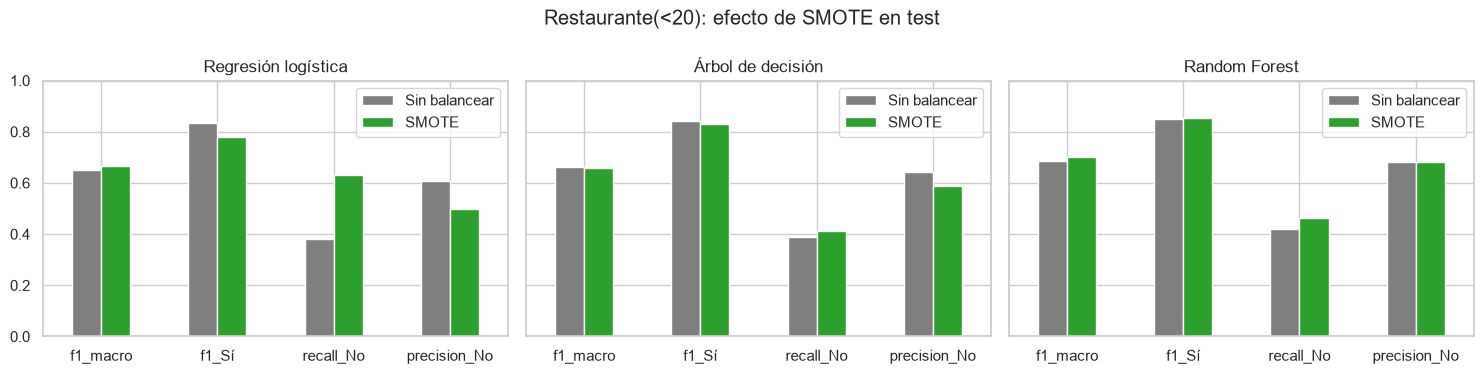

In [20]:
res = pd.DataFrame(resultados)
comp = res[res["cupon"] == R].set_index("modelo")[["f1_macro_cv", "f1_macro", "f1_Sí", "f1_No",
                                                    "recall_No", "precision_No", "recall_Sí"]]
comp = comp.reindex(["Regresión logística", "Regresión logística + SMOTE", "Árbol de decisión",
                     "Árbol de decisión + SMOTE", "Random Forest", "Random Forest + SMOTE"])
display(comp.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, alg in zip(axes, ["Regresión logística", "Árbol de decisión", "Random Forest"]):
    sub = comp.loc[[alg, alg + " + SMOTE"], ["f1_macro", "f1_Sí", "recall_No", "precision_No"]].T
    sub.columns = ["Sin balancear", "SMOTE"]
    sub.plot.bar(ax=ax, rot=0, color=["#7f7f7f", "#2ca02c"]); ax.set_title(alg); ax.set_ylim(0, 1)
plt.suptitle("Restaurante(<20): efecto de SMOTE en test"); plt.tight_layout(); plt.show()

### 6.1 Conclusión sobre el balanceo

| Algoritmo | F1 macro sin → con SMOTE | Recall `No` sin → con SMOTE | F1 `Sí` sin → con SMOTE |
|---|---|---|---|
| Regresión logística | 0,652 → 0,668 | 0,383 → **0,630** | 0,834 → 0,780 |
| Árbol de decisión | 0,663 → 0,657 | 0,389 → 0,414 | 0,842 → 0,829 |
| Random Forest | 0,685 → **0,703** | 0,420 → 0,463 | 0,851 → 0,854 |

- **El efecto depende del algoritmo.**
  - En la **regresión logística**, SMOTE desplaza la frontera de decisión: el recall de la clase minoritaria sube de 0,38 a 0,63 (+25 puntos) y el F1 macro mejora. El costo es la precisión de `No` (0,61 → 0,50) y el F1 de `Sí`.
  - En el **árbol de decisión** prácticamente no cambia nada. El F1 macro baja levemente y la búsqueda eligió un árbol muy poco profundo, porque los puntos sintéticos le añaden ruido.
  - En el **Random Forest**, SMOTE mejora a la vez el F1 macro (+0,018), el recall de `No` (+4 puntos) y el F1 de `Sí`, sin perder precisión en `No`. Es la única configuración en la que todas las métricas mejoran o se mantienen.
- **Recomendación:** aplicar SMOTE en Restaurante(<20) con el Random Forest, que además es el mejor modelo global para este cupón. La mejora es moderada pero consistente en validación cruzada (0,704 → 0,712) y en test (0,685 → 0,703).
- Aun así, el recall de `No` sigue por debajo de 0,5. Si para Ruta Alpes es prioritario **no molestar** a quien va a rechazar el cupón, convendría además **ajustar el umbral de decisión** o usar `class_weight`, según el costo relativo de cada error.

## 7. Tabla comparativa de desempeño en test
Precisión, recall y F1 de la clase positiva (`Sí`) y de la clase `No`, junto con el F1 macro (criterio de selección). Se incluyen las variantes con SMOTE de Restaurante(<20).

In [21]:
res = pd.DataFrame(resultados)
tabla = res.set_index(["cupon", "modelo"])[["precision_Sí", "recall_Sí", "f1_Sí", "precision_No",
                                            "recall_No", "f1_No", "f1_macro", "f1_macro_cv"]]
display(tabla.style.format("{:.3f}").highlight_max(subset=["f1_macro"], color="#c6efce")
        .set_caption("Desempeño en test por cupón y modelo"))

mejores = {}
for c in CUPONES:
    t = res[res["cupon"] == c].sort_values("f1_macro", ascending=False)
    mejores[c] = t.iloc[0]["modelo"]
    print(f"Mejor modelo para {c}: {mejores[c]} (F1 macro test = {t.iloc[0]['f1_macro']:.4f}, "
          f"F1 macro CV = {t.iloc[0]['f1_macro_cv']:.4f})")

Mejor modelo para Cafetería: Random Forest (F1 macro test = 0.7789, F1 macro CV = 0.7617)
Mejor modelo para Restaurante(<20): Random Forest + SMOTE (F1 macro test = 0.7028, F1 macro CV = 0.7116)


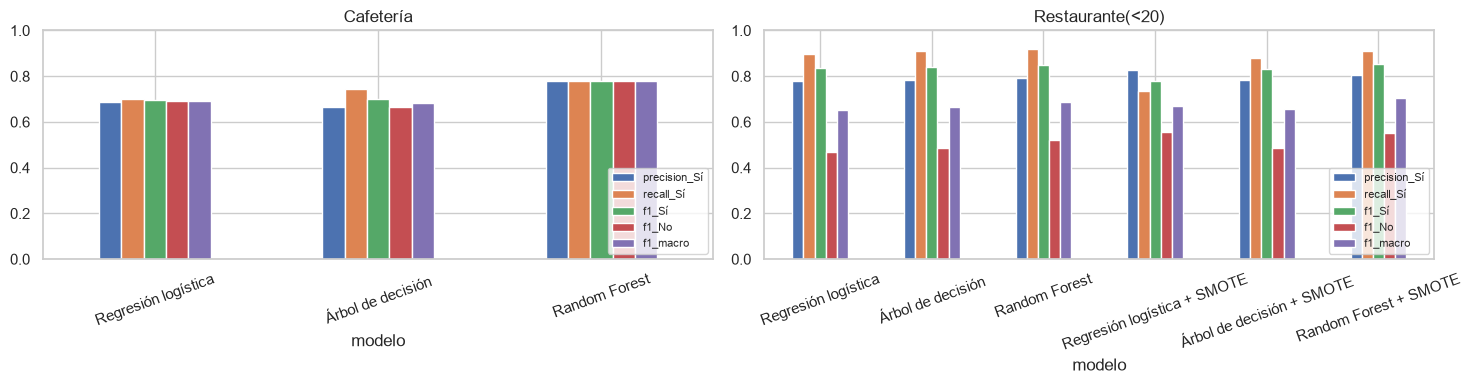

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, c in zip(axes, CUPONES):
    t = res[res["cupon"] == c].set_index("modelo")[["precision_Sí", "recall_Sí", "f1_Sí", "f1_No", "f1_macro"]]
    t.plot.bar(ax=ax, rot=20); ax.set_ylim(0, 1); ax.set_title(c); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### 7.1 Selección del mejor modelo

- **Cafetería → Random Forest** (500 árboles, sin límite de profundidad, `min_samples_leaf=1`, `max_features='sqrt'`).
  - F1 macro de **0,779** en test (0,762 en CV), con precisión y recall ≈ 0,78 en ambas clases.
  - Supera por ≈ 9 puntos a la regresión logística (0,692) y al árbol (0,684), que quedan prácticamente empatados.
- **Restaurante(<20) → Random Forest + SMOTE** (500 árboles, `max_features='sqrt'`).
  - F1 macro de **0,703** en test (0,712 en CV). Es el mejor en F1 macro, F1 `Sí` (0,854) y precisión `No`.
  - En recall de `No` lo supera la regresión logística con SMOTE (0,630), pero a costa de mucha precisión.

**Por qué gana el Random Forest.** El problema tiene muchas variables categóricas e **interacciones**: por ejemplo, el hábito de ir a cafeterías importa sobre todo cuando no hay destino urgente. La regresión logística, que es lineal y aditiva, no las captura sin ingeniería de variables. Un árbol individual sí las captura, pero tiene alta varianza: su F1 en CV es mayor que en test. El *bagging* con submuestreo de variables del Random Forest reduce esa varianza.

**Consistencia entre CV y test.** Las diferencias entre F1 en CV y en test son pequeñas (≤ 0,03), lo que indica que los modelos elegidos no están sobreajustados a la partición de test.

## 8. Variables más relevantes

Usamos tres miradas complementarias:
1. **Importancia por permutación** sobre test del mejor modelo de cada cupón. Se mide sobre las variables *originales*, antes de la codificación, y es agnóstica al modelo: cuánto cae el F1 macro al desordenar cada variable.
2. **Importancia por impureza (MDI)** del Random Forest, agregando las columnas *one-hot* a su variable original.
3. **Coeficientes de la regresión logística**, que indican la dirección del efecto (sobre variables estandarizadas).

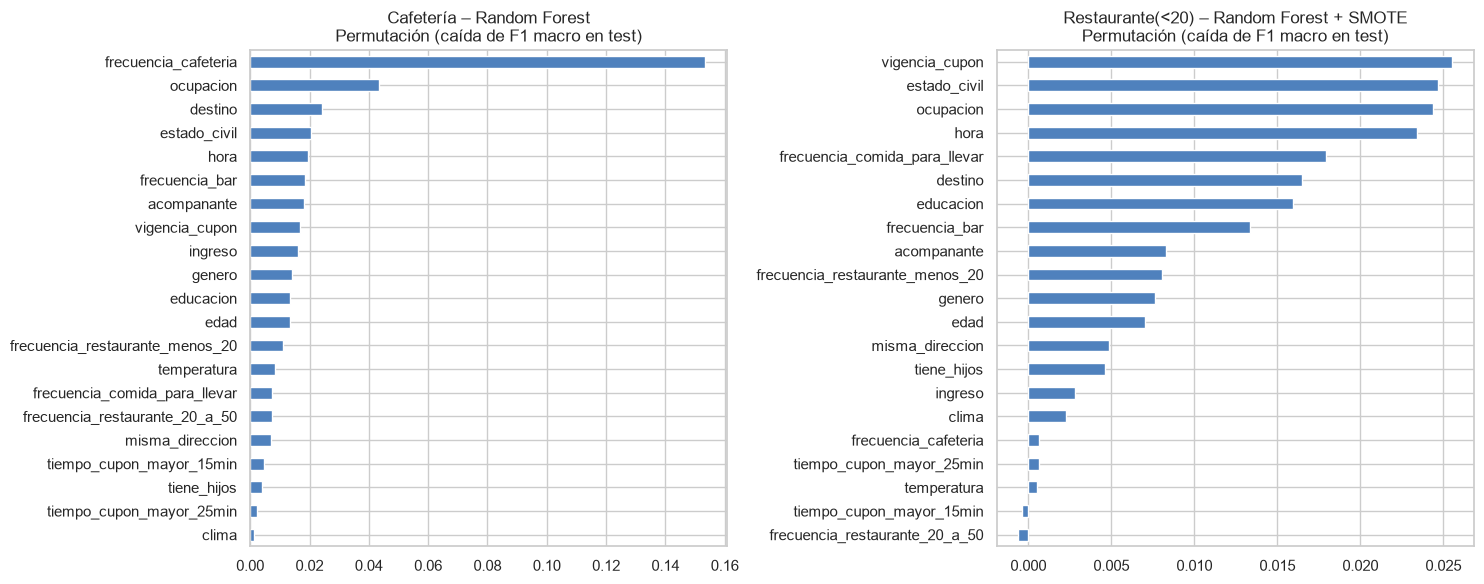

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,0.1532,0.0006
ocupacion,0.0434,0.0244
destino,0.0242,0.0165
estado_civil,0.0206,0.0247
hora,0.0195,0.0234
frecuencia_bar,0.0185,0.0133
acompanante,0.0182,0.0083
vigencia_cupon,0.0169,0.0255
ingreso,0.0161,0.0028
genero,0.0140,0.0076


In [23]:
perm = {}
for c in CUPONES:
    d = datos[c]
    pi = permutation_importance(modelos[(c, mejores[c])], d["X_te"], d["y_te"], scoring="f1_macro",
                                n_repeats=20, random_state=SEED, n_jobs=-1)
    perm[c] = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, c in zip(axes, CUPONES):
    perm[c].iloc[::-1].plot.barh(ax=ax, color="#4f81bd")
    ax.set_title(f"{c} – {mejores[c]}\nPermutación (caída de F1 macro en test)")
plt.tight_layout(); plt.show()
pd.DataFrame(perm).round(4).sort_values("Cafetería", ascending=False)

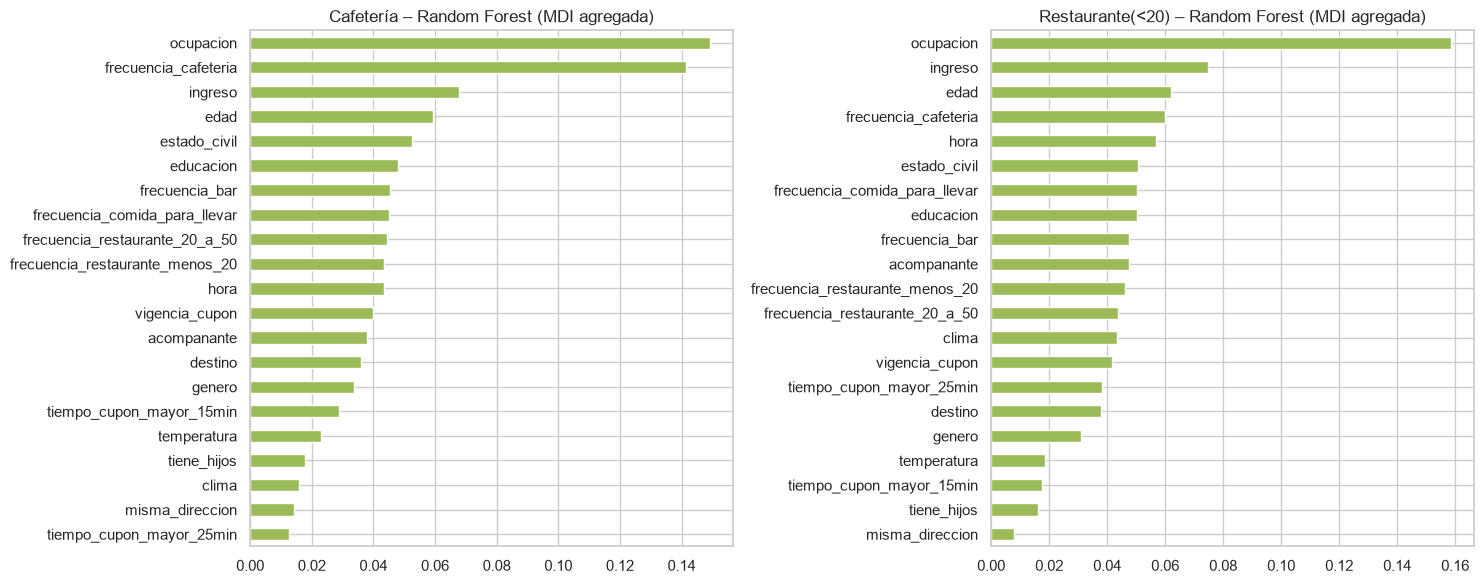

In [24]:
def a_variable_original(nombre):
    if nombre in NUM_COLS + ORD_COLS:
        return nombre
    return next(c for c in NOM_COLS if nombre.startswith(c + "_"))

mdi = {}
for c in CUPONES:
    best = modelos[(c, "Random Forest")].best_estimator_
    nombres = best.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(best.named_steps["clf"].feature_importances_, index=nombres)
    mdi[c] = imp.groupby(imp.index.map(a_variable_original)).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, c in zip(axes, CUPONES):
    mdi[c].iloc[::-1].plot.barh(ax=ax, color="#9bbb59"); ax.set_title(f"{c} – Random Forest (MDI agregada)")
plt.tight_layout(); plt.show()

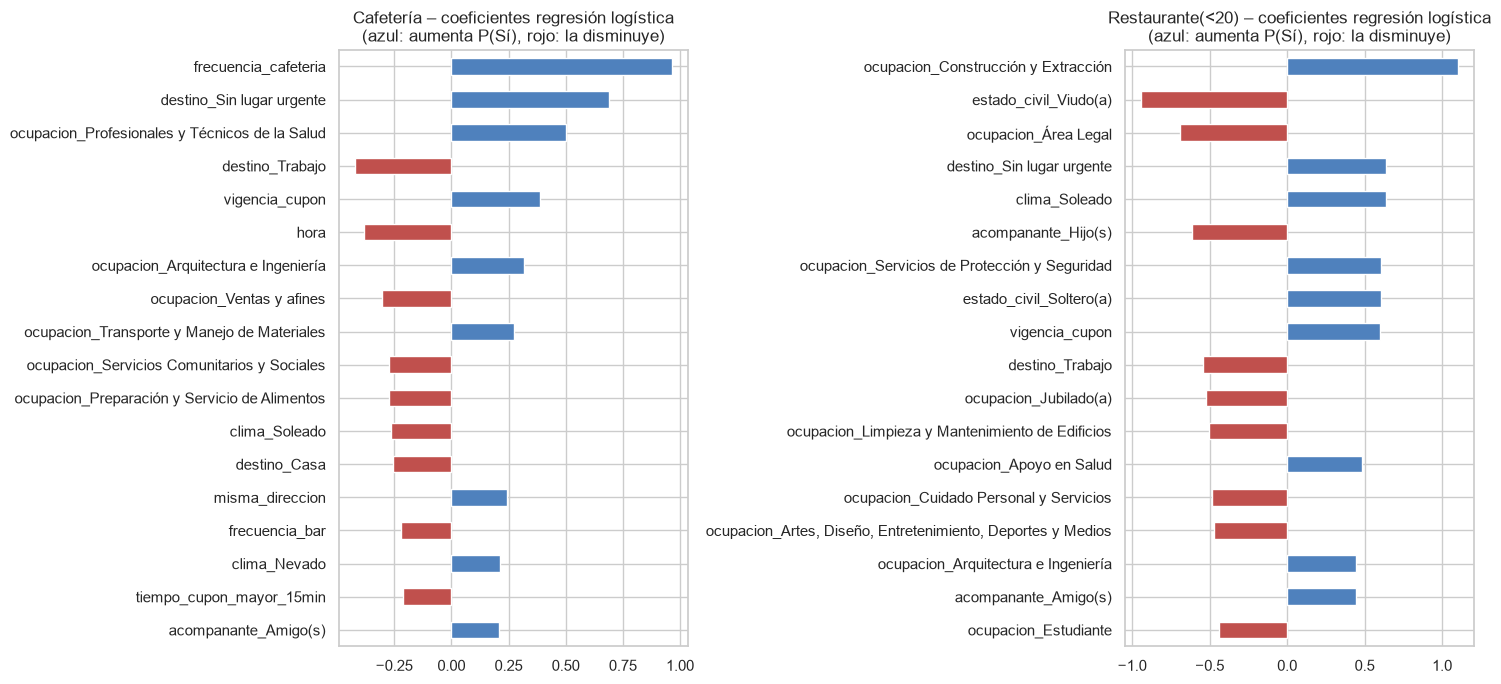

In [25]:
coefs = {}
for c in CUPONES:
    best = modelos[(c, "Regresión logística")].best_estimator_
    nombres = best.named_steps["prep"].get_feature_names_out()
    coefs[c] = pd.Series(best.named_steps["clf"].coef_[0], index=nombres)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, c in zip(axes, CUPONES):
    s = coefs[c]
    top = s.reindex(s.abs().sort_values(ascending=False).index[:18]).iloc[::-1]
    top.plot.barh(ax=ax, color=np.where(top > 0, "#4f81bd", "#c0504d"))
    ax.set_title(f"{c} – coeficientes regresión logística\n(azul: aumenta P(Sí), rojo: la disminuye)")
plt.tight_layout(); plt.show()

### 8.1 Reglas de un árbol de decisión
Para interpretar con reglas legibles, ajustamos sobre train un árbol con los mejores hiperparámetros pero limitado a profundidad 3. El árbol completo es demasiado grande para leerlo; este solo sirve para interpretar, no para predecir. Mostramos además su F1 macro en test, para dimensionar cuánto desempeño se sacrifica a cambio de legibilidad.

===== Cafetería | árbol de profundidad 3 | F1 macro test = 0.691
Nota: las ordinales están codificadas como posición en su orden (p. ej. frecuencia 0=nunca … 4=más de 8; hora 0=7am … 4=10pm; vigencia 0=2 horas, 1=1 día).
|--- frecuencia_cafeteria <= 0.50
|   |--- ingreso <= 5.50
|   |   |--- frecuencia_restaurante_20_a_50 <= 1.50
|   |   |   |--- weights: [349.00, 86.00] class: No
|   |   |--- frecuencia_restaurante_20_a_50 >  1.50
|   |   |   |--- weights: [59.00, 40.00] class: No
|   |--- ingreso >  5.50
|   |   |--- destino_Casa <= 0.50
|   |   |   |--- weights: [136.00, 17.00] class: No
|   |   |--- destino_Casa >  0.50
|   |   |   |--- weights: [49.00, 0.00] class: No
|--- frecuencia_cafeteria >  0.50
|   |--- destino_Sin lugar urgente <= 0.50
|   |   |--- misma_direccion <= 0.50
|   |   |   |--- weights: [419.00, 259.00] class: No
|   |   |--- misma_direccion >  0.50
|   |   |   |--- weights: [163.00, 280.00] class: Sí
|   |--- destino_Sin lugar urgente >  0.50
|   |   |--- frecu

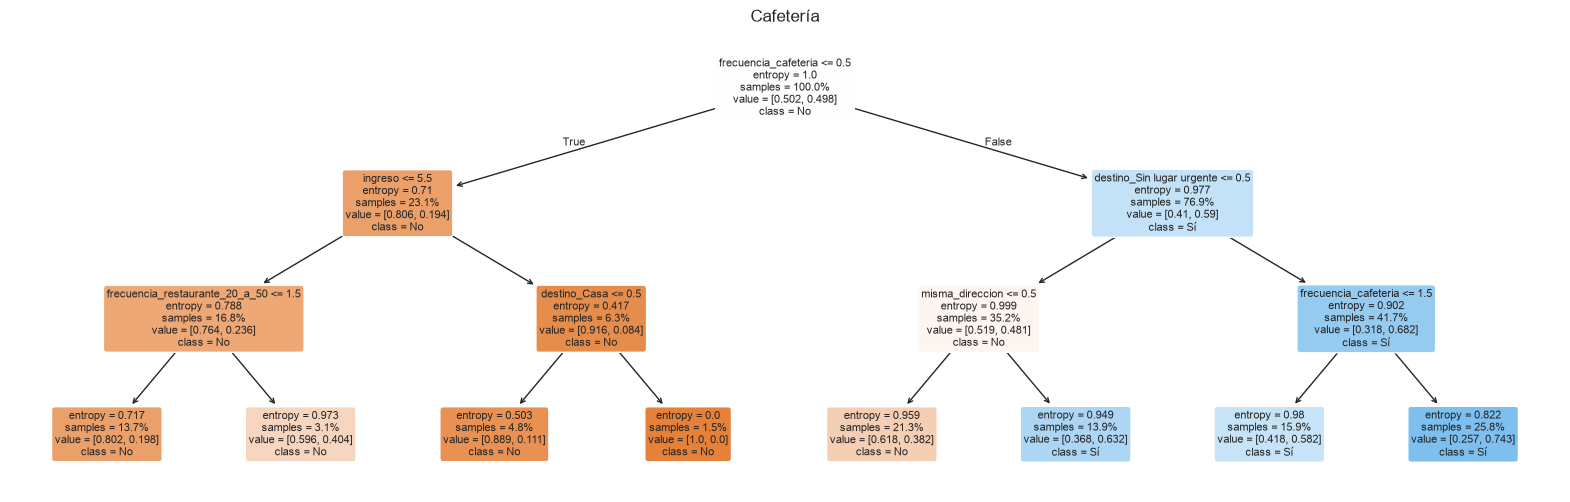

===== Restaurante(<20) | árbol de profundidad 3 | F1 macro test = 0.658
Nota: las ordinales están codificadas como posición en su orden (p. ej. frecuencia 0=nunca … 4=más de 8; hora 0=7am … 4=10pm; vigencia 0=2 horas, 1=1 día).
|--- tiempo_cupon_mayor_25min <= 0.50
|   |--- vigencia_cupon <= 0.50
|   |   |--- hora <= 3.50
|   |   |   |--- weights: [210.00, 521.00] class: Sí
|   |   |--- hora >  3.50
|   |   |   |--- weights: [97.00, 92.00] class: No
|   |--- vigencia_cupon >  0.50
|   |   |--- temperatura <= 42.50
|   |   |   |--- weights: [47.00, 117.00] class: Sí
|   |   |--- temperatura >  42.50
|   |   |   |--- weights: [128.00, 756.00] class: Sí
|--- tiempo_cupon_mayor_25min >  0.50
|   |--- acompanante_Solo <= 0.50
|   |   |--- weights: [4.00, 19.00] class: Sí
|   |--- acompanante_Solo >  0.50
|   |   |--- frecuencia_bar <= 2.50
|   |   |   |--- weights: [135.00, 59.00] class: No
|   |   |--- frecuencia_bar >  2.50
|   |   |   |--- weights: [27.00, 3.00] class: No



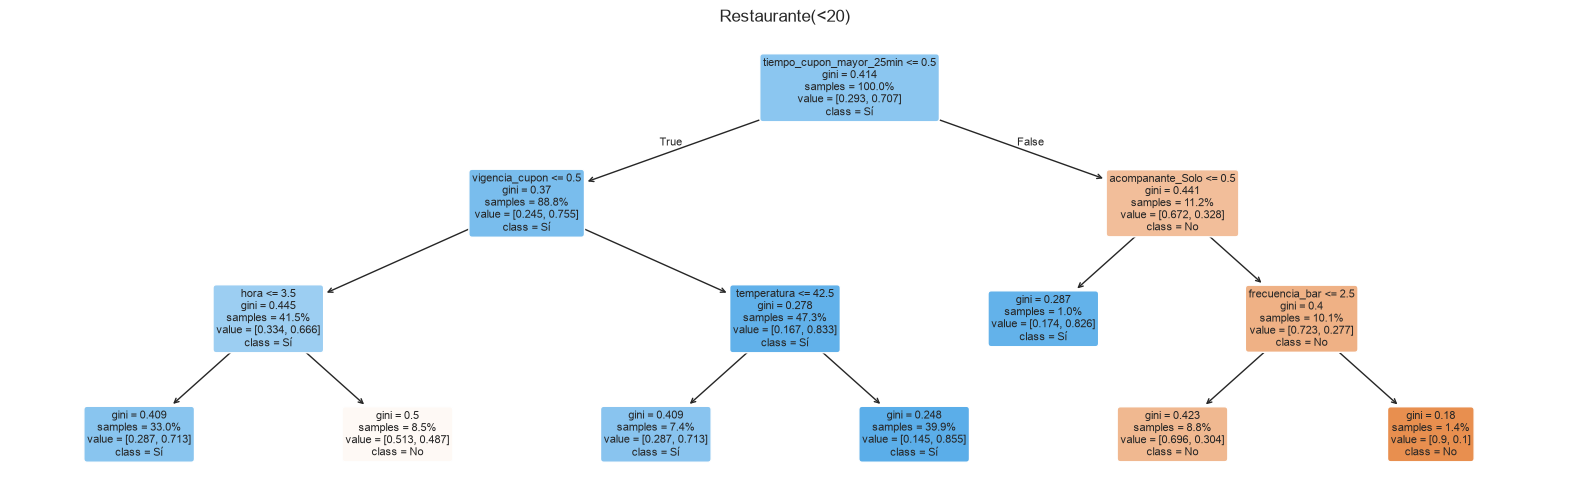

In [26]:
for c in CUPONES:
    d = datos[c]
    params = {k.replace("clf__", ""): v for k, v in modelos[(c, "Árbol de decisión")].best_params_.items()}
    params["max_depth"] = 3
    arbol = Pipeline([("prep", preprocesador(False)), ("clf", DecisionTreeClassifier(random_state=SEED, **params))])
    arbol.fit(d["X_tr"], d["y_tr"])
    nombres = list(arbol.named_steps["prep"].get_feature_names_out())
    print(f"===== {c} | árbol de profundidad 3 | F1 macro test = "
          f"{f1_score(d['y_te'], arbol.predict(d['X_te']), average='macro'):.3f}")
    print("Nota: las ordinales están codificadas como posición en su orden (p. ej. frecuencia 0=nunca … 4=más de 8; "
          "hora 0=7am … 4=10pm; vigencia 0=2 horas, 1=1 día).")
    print(export_text(arbol.named_steps["clf"], feature_names=nombres, class_names=["No", "Sí"], show_weights=True))
    plt.figure(figsize=(20, 6))
    plot_tree(arbol.named_steps["clf"], feature_names=nombres, class_names=["No", "Sí"], filled=True,
              rounded=True, fontsize=8, proportion=True)
    plt.title(c); plt.show()

### 8.2 Síntesis de variables relevantes

**Cafetería**
- **`frecuencia_cafeteria`** es, de lejos, la variable más importante en las tres miradas:
  - por permutación, su caída de F1 (0,153) es más de tres veces la de la siguiente;
  - en la regresión logística tiene el coeficiente más grande (+0,97);
  - es la raíz del árbol.
- Le siguen variables de **contexto**:
  - `destino`: `Sin lugar urgente` aumenta la probabilidad de aceptar y `Trabajo`/`Casa` la reducen;
  - `hora`: a más tarde, menos aceptación;
  - `vigencia_cupon`: la de 1 día aumenta la aceptación;
  - `acompanante` y `misma_direccion`.
- Entre las demográficas, la `ocupacion` aparece como relevante; el resto (`edad`, `genero`, `ingreso`, `educacion`) aporta poco.

**Restaurante(<20)**
- La importancia está **más repartida** y ninguna variable domina.
- Destacan las de **contexto**:
  - `vigencia_cupon`, `hora` y `destino`;
  - la distancia (`tiempo_cupon_mayor_25min`), que es la raíz del árbol interpretable;
  - `clima`/`temperatura` (con sol se acepta más);
  - el `acompanante`: con hijos se acepta menos que con amigos.
- También aparecen `ocupacion` y `estado_civil`.
- A diferencia de Cafetería, el hábito específico (`frecuencia_restaurante_menos_20`) tiene **poca** importancia.

**Precauciones de lectura**
- La importancia por impureza (MDI) **favorece a variables con muchas categorías o niveles**. `ocupacion` (25 categorías) e `ingreso` (9 niveles) salen arriba en MDI, pero su importancia por permutación es mucho menor. Por eso la permutación en test es la referencia principal.
- Entre variables **correlacionadas** la importancia se reparte. Así, `tiempo_cupon_mayor_25min`, que es muy discriminativa en el análisis exploratorio, sale baja en permutación porque `tiempo_cupon_mayor_15min`, `destino` y `hora` capturan parte de esa información. Lo mismo ocurre con `clima` y `temperatura`.

## 9. Análisis de resultados

**1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?**

- **Cafetería.** Lo más relacionado es el **hábito previo**: `frecuencia_cafeteria` es la variable más importante en todos los análisis, y quien nunca va a cafeterías casi nunca acepta (19%). Después pesa el contexto:
  - viajar **sin destino urgente** (58% vs 36% hacia casa);
  - la **hora** (la mañana, 10 a.m., es el mejor momento);
  - la **vigencia** de 1 día;
  - ir **acompañado**;
  - que el local **no esté lejos** (más de 25 min reduce la aceptación al 35%).
- **Restaurante(<20).** Dominan las variables de **contexto del viaje**:
  - **vigencia** (83% con 1 día vs 59%);
  - **distancia** (33% si el local está a más de 25 min);
  - **clima** (77% con sol vs 39% con lluvia);
  - **hora** (mediodía y tarde, 2–6 p.m.);
  - **destino** sin urgencia;
  - **acompañante** (con amigos o pareja más que solo o con hijos).

  Del perfil, la `ocupacion` y el `estado_civil` aportan algo, pero el hábito de ir a restaurantes baratos es poco informativo.

**2. ¿Existen variables que podrían ser redundantes o poco informativas?**

Sí:
- **Redundantes o constantes, eliminadas en la preparación:**
  - `direccion_opuesta`, que es el complemento exacto de `misma_direccion`;
  - `tiempo_cupon_mayor_5min`, que es constante;
  - `vehiculo`, con ≈ 99% de nulos.
- **Parcialmente redundantes:**
  - `temperatura` respecto a `clima` (solo varía dentro de `Soleado`);
  - `tiempo_cupon_mayor_25min`, anidada en `tiempo_cupon_mayor_15min`.
- **Poco informativas según la permutación** (importancia ≈ 0 en uno o ambos cupones):
  - `clima`, `tiempo_cupon_mayor_25min` y `tiene_hijos`;
  - `frecuencia_restaurante_20_a_50` en Restaurante;
  - las frecuencias de *otros* tipos de lugar (`frecuencia_cafeteria` es casi irrelevante para Restaurante).

  Esto no significa que no tengan relación individual con el objetivo. Su información ya está contenida en otras variables.
- **Demográficas** (`genero`, `edad`, `educacion`, `tiene_hijos`): las diferencias en tasa de aceptación entre sus grupos son pequeñas, así que podrían eliminarse con poca pérdida de desempeño. Esto es relevante para la discusión ética de las preguntas 7 y 8.

**3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué atribuye esa diferencia?**

Sí:
- **Desempeño.** El mejor modelo logra un F1 macro de 0,78 en Cafetería y de 0,70 en Restaurante(<20).
  - En Cafetería las dos clases se predicen igual de bien (≈ 0,78).
  - En Restaurante la clase `Sí` se predice muy bien (F1 0,85), pero la `No` mal (F1 0,55, recall 0,46).
- **Causas:**
  1. **Desbalance.** Restaurante tiene 71/29, así que los modelos tienden a favorecer la clase mayoritaria y ven menos ejemplos de rechazo.
  2. **Tamaño.** Hay 2.769 registros de Restaurante frente a 3.979 de Cafetería.
  3. **Naturaleza de la decisión.** En Cafetería existe un predictor fuerte e individual: el hábito de ir a cafeterías separa claramente a quien nunca acepta. En Restaurante la decisión depende de **combinaciones del contexto** (clima, hora, distancia, vigencia) y no hay un rasgo del conductor que explique bien los rechazos. La señal está más repartida y es más ruidosa.
  4. **Hiperparámetros.** En Restaurante la búsqueda eligió modelos con más capacidad de interacción (árbol de profundidad 10 frente a 5; `max_features=0.3` en el RF sin SMOTE), coherente con esa estructura más compleja.

**4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general como el recall de la clase minoritaria.**

Depende del algoritmo (detalle en la sección 6.1):
- **Random Forest:** sí mejoró. El F1 macro pasa de 0,685 a 0,703 y el recall de `No` de 0,42 a 0,46, sin perder F1 de `Sí` (0,851 → 0,854) ni precisión de `No`. La mejora también se observa en CV, así que no es un efecto del azar de la partición.
- **Regresión logística:** SMOTE produce el mayor salto en recall de la minoritaria (0,38 → 0,63), pero a costa de precisión de `No` (0,61 → 0,50) y de F1 de `Sí`. La mejora en F1 macro es pequeña (0,652 → 0,668).
- **Árbol:** no mejoró.

**Conclusión:** conviene aplicar SMOTE junto con el Random Forest, que es el modelo seleccionado. Si el objetivo de negocio fuera minimizar notificaciones molestas (detectar a quien rechaza), el recall de `No` aún es bajo y convendría combinar el balanceo con un ajuste del umbral de decisión.

**5. A partir de alguno de los modelos de árbol o Random Forest describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.**

Usamos el árbol interpretable de profundidad 3 (sección 8.1) y las importancias del Random Forest.

- **Cafetería**
  - **Rechazo:** si el conductor **nunca va a cafeterías**, el árbol predice `No` en todas las ramas. Con ingresos altos (≥ \$75.000) y destino casa, el rechazo es total (49 de 49).
  - **Aceptación:** si va a cafeterías, **viaja sin destino urgente** y va al menos 1 vez al mes, acepta en ≈ 74% de los casos (610 de 821). Si sí tiene destino, acepta cuando la cafetería está **en su misma dirección** (63%).
- **Restaurante(<20)**
  - **Rechazo:** si el local está a **más de 25 min** y el conductor **va solo**, la regla predice rechazo (≈ 70–90% de `No`). Con vigencia de 2 horas y **hora de 10 p.m.**, predomina levemente el rechazo (51%).
  - **Aceptación:** si está a menos de 25 min, la vigencia es de **1 día** y no hace frío, acepta en ≈ 86% de los casos (756 de 884).
- El Random Forest confirma estas variables (hábito, destino, hora, vigencia, distancia) como las más importantes por permutación.

**Utilidad.** Las reglas son comprensibles para el negocio y se pueden traducir en políticas: "no ofrecer cafetería a quien nunca va", "no ofrecer restaurantes lejanos a quien conduce solo", "preferir cupones de 1 día". También permiten auditar si el modelo usa variables sensibles.

**Limitaciones:**
- el árbol simplificado pierde desempeño (F1 0,69 y 0,66 frente a 0,78 y 0,70 del RF), así que es una *aproximación* del modelo real;
- un único árbol es inestable: pequeños cambios en los datos cambian las reglas;
- la importancia de variables indica **asociación, no causalidad**;
- la importancia no dice la dirección del efecto y se reparte entre variables correlacionadas;
- el MDI sobreestima variables con muchas categorías.

**6. ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?**

1. **Entrada.** Cuando hay un local con cupón cerca de la ruta, la app arma el vector de características combinando:
   - el **contexto** que conoce en ese momento: destino, hora, clima/temperatura, acompañantes, dirección y tiempo hasta el local, vigencia del cupón;
   - el **perfil** del usuario, guardado y actualizado periódicamente.
2. **Inferencia.** El pipeline entrenado (preprocesamiento + modelo serializado con `joblib`) se expone como un servicio ligero o se ejecuta en el dispositivo. Predecir con un Random Forest toma milisegundos.
3. **Decisión.** Para cada cupón candidato se obtiene la **probabilidad de aceptación** y se muestra el de mayor probabilidad, solo si supera un **umbral** definido por el negocio según el costo de molestar frente al de perder una venta. Se añaden reglas de seguridad: no notificar en maniobras complejas ni a alta velocidad, limitar el número de ofertas por trayecto.
4. **Retroalimentación.** Se registran aceptaciones y rechazos para **reentrenar** periódicamente, **monitorear** la deriva de datos y del desempeño por segmento, y hacer **pruebas A/B** contra la estrategia actual.

**7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?**

- **Desempeño limitado:**
  - con F1 de 0,70–0,78, una de cada cuatro o cinco decisiones es errónea;
  - en Restaurante se identifica menos de la mitad de los rechazos, lo que se traduce en notificaciones molestas.
- **Datos de encuesta e hipotéticos:**
  - el conjunto proviene de escenarios planteados a los encuestados, no de comportamiento real;
  - la intención declarada difiere de la conducta;
  - la muestra puede no representar a la población de usuarios de Ruta Alpes.
- **Perfil estático y desactualizado:** ingresos, estado civil o hábitos cambian, y la app puede no saberlo.
- **Bucles de retroalimentación:** si a un grupo nunca se le muestran ciertos cupones, nunca se recogen datos de su aceptación y el sistema "confirma" su propio sesgo.
- **Poca señal demográfica:** las variables demográficas aportan poco al desempeño; el contexto y los hábitos explican más. Usarlas introduce riesgos con escaso beneficio.
- **Privacidad y regulación:** procesar edad, estado civil o ingresos requiere consentimiento explícito y finalidad clara (por ejemplo, la Ley 1581 de 2012 de protección de datos en Colombia).
- **Explicabilidad:** el usuario no sabe por qué ve una oferta, y un Random Forest es difícil de explicar caso a caso.

**8. ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?**

**Fuentes de sesgo:**
- **Sesgo de muestreo o representación:** algunos grupos tienen muy pocos registros, por ejemplo viudos(as), menores de 21 o varias ocupaciones con menos de 50 casos. Sus tasas de aceptación son poco fiables y el modelo puede aprender patrones espurios sobre ellos. Por ejemplo, el coeficiente de `estado_civil_Viudo(a)` es de los más negativos en Restaurante.
- **Sesgo de medición:**
  - variables autodeclaradas (ingreso, frecuencias) y categorías amplias;
  - `genero` binario, que no representa a todas las personas;
  - datos hipotéticos de encuesta.
- **Variables proxy:** aunque se eliminen género o edad, otras variables pueden sustituirlas (ocupación como "Estudiante" o "Jubilado(a)" frente a edad; ingreso frente a educación u ocupación). Eliminar la variable no elimina el sesgo.
- **Sesgo histórico y de agregación:** el modelo reproduce patrones pasados de consumo, que reflejan desigualdades de acceso. Un solo modelo para todos puede funcionar peor para grupos minoritarios. Recomendamos **medir el desempeño por subgrupo** (recall/precisión por género, edad, ingreso) antes de desplegar.
- **Sesgo del proceso de modelado:**
  - SMOTE genera ejemplos sintéticos que pueden amplificar patrones de grupos pequeños;
  - la elección de la métrica y del umbral favorece unos errores sobre otros.

**Implicaciones fuera de los cupones.** En cupones, el daño de un error es pequeño: una notificación irrelevante o un descuento no ofrecido. Pero si la misma lógica se usara para **precios dinámicos**, seguros, crédito o acceso a servicios, la personalización por edad, género, estado civil o ingreso podría convertirse en **discriminación de precios**:
- cobrar más a quien el modelo estima con mayor disposición a pagar o menos alternativas;
- excluir sistemáticamente a ciertos grupos de los beneficios.

Eso afecta la equidad, puede ser ilegal en varias jurisdicciones y erosiona la confianza de los usuarios.

**Recomendaciones:**
- priorizar variables de **contexto** y de **hábitos con consentimiento** sobre las demográficas;
- auditar la equidad entre grupos;
- ser transparentes con el usuario (por qué ve una oferta y opción de excluirse);
- no reutilizar estos modelos para fijar precios sin una evaluación ética y legal específica.

## 10. Predicciones sobre `Lab3_datos_Prueba`
Para cada cupón tomamos el mejor modelo de la sección 7 (con sus hiperparámetros óptimos) y lo **reentrenamos con todos los datos etiquetados** de ese cupón (train + test), para aprovechar el máximo de información. Luego predecimos las 20 filas sin etiqueta. El CSV conserva todas las columnas del archivo original y añade `acepta_cupon` (`Sí`/`No`).

In [27]:
prueba = pd.read_excel("Data/Lab3_datos_Prueba.xlsx")
print("Dimensiones de prueba:", prueba.shape)
print(prueba["cupon"].value_counts())

pred = pd.Series(index=prueba.index, dtype=object)
for c in CUPONES:
    final = clone(modelos[(c, mejores[c])].best_estimator_)
    final.fit(datos[c]["X"], datos[c]["y"])
    idx = prueba["cupon"] == c
    Xp = limpiar(prueba.loc[idx])[FEATURES]
    pred[idx] = np.where(final.predict(Xp) == 1, "Sí", "No")
    print(f"{c}: modelo = {mejores[c]} | predicciones -> {pred[idx].value_counts().to_dict()}")

salida = prueba.copy()
salida["acepta_cupon"] = pred
assert salida["acepta_cupon"].notna().all()
salida.to_csv("Lab3_datos_Prueba.csv", index=False, encoding="utf-8-sig")
print("\nArchivo guardado: Lab3_datos_Prueba.csv")
salida[["cupon", "destino", "acompanante", "hora", "acepta_cupon"]]

Dimensiones de prueba: (20, 25)
cupon
Cafetería           10
Restaurante(<20)    10
Name: count, dtype: int64


Cafetería: modelo = Random Forest | predicciones -> {'Sí': 6, 'No': 4}


Restaurante(<20): modelo = Random Forest + SMOTE | predicciones -> {'Sí': 9, 'No': 1}

Archivo guardado: Lab3_datos_Prueba.csv


,cupon,destino,acompanante,hora,acepta_cupon
0,Cafetería,Trabajo,Solo,7:00 a.m.,Sí
1,Cafetería,Sin lugar urgente,Amigo(s),10:00 a.m.,Sí
2,Cafetería,Sin lugar urgente,Amigo(s),2:00 p.m.,Sí
3,Cafetería,Sin lugar urgente,Pareja,10:00 a.m.,Sí
4,Restaurante(<20),Sin lugar urgente,Amigo(s),6:00 p.m.,Sí
5,Restaurante(<20),Sin lugar urgente,Hijo(s),2:00 p.m.,Sí
6,Restaurante(<20),Sin lugar urgente,Solo,2:00 p.m.,No
7,Restaurante(<20),Sin lugar urgente,Amigo(s),6:00 p.m.,Sí
8,Restaurante(<20),Sin lugar urgente,Amigo(s),2:00 p.m.,Sí
9,Cafetería,Casa,Solo,6:00 p.m.,No


## 11. Uso de herramientas de IA generativa

**Declaración del uso**
- **Herramienta:** Claude Code (modelo Claude Opus 5.5, de Anthropic), usado desde la aplicación de escritorio con acceso a la carpeta del laboratorio.
- **Tipo de uso:**
  - análisis inicial del enunciado y de los archivos de datos;
  - **generación inicial del código** del notebook: exploración, pipelines, rejillas de hiperparámetros, SMOTE, tabla comparativa, importancia de variables y exportación de predicciones;
  - **borrador de redacción** de las conclusiones y del análisis de resultados a partir de las salidas obtenidas.

**Prompts utilizados (textuales)**
1. *"analisa esta carpeta y lo que toca hacer"*. La herramienta leyó el enunciado y los tres archivos de Excel y resumió las actividades, los hallazgos de calidad de datos (nulos en `vehiculo`, columna constante, redundancias, desbalance en Restaurante(<20)) y los entregables.
2. *"Crea el notebook completo: exploración, limpieza, los tres modelos con GridSearchCV, SMOTE, tabla comparativa, importancia de variables y el CSV de predicciones."*

> _Agregar aquí cualquier otro prompt relevante que hayan usado (p. ej. preguntas conceptuales o de depuración)._

**Análisis crítico del resultado**
> ✏️ _Sección por completar por los integrantes, respondiendo al menos dos de las preguntas: ¿Qué partes fueron correctas y útiles? ¿Qué errores, imprecisiones o limitaciones identificaron? ¿Qué decisiones técnicas modificaron y por qué? ¿Qué conceptos del curso les permitieron evaluar la respuesta?_
>
> Puntos que pueden revisar: (i) que SMOTE se aplique **dentro** del pipeline y solo a train; (ii) la elección de F1 macro como métrica de selección; (iii) la limitación de aplicar SMOTE sobre variables *one-hot* (SMOTENC como alternativa); (iv) el sesgo de la importancia MDI hacia variables de alta cardinalidad; (v) el uso de `l1_ratio` en lugar de `penalty` por la obsolescencia en scikit-learn ≥ 1.8.

**Aportes propios de los estudiantes**
> ✏️ _Sección por completar por los integrantes: qué desarrollaron, modificaron o decidieron ustedes; qué ajustes hicieron al código o a la redacción; qué aprendieron en el proceso._